# 22. Modelo propuesto: A+B v2

Este capítulo presenta el modelo original del proyecto, el protocolo con que se evaluó, la independencia de la
evaluación y los resultados frente a los benchmark en la **evaluación
definitiva en origen móvil 2021–2026** (cap. 13.11): 69 meses, modelos reentrenados cada año.

In [1]:
# Localiza la raíz del libro (la carpeta con _config.yml) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not (raiz / "_config.yml").exists():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [2]:
# Predicciones del origen móvil y módulos estadísticos
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import roc_auc_score
from src import resultados_e2 as r2, estadistica as est
ev_, X, info, tr, gp, te = datos.panel_completo()
y = info["y"].astype(float); tm = info["tm"]; tmt = tm[te]
O, Fi = r2.origen_movil(), r2.filas_origen_movil()
yo, tmo = O["y"], O["tm"]
persist, estac = info["C"][Fi["cc"], Fi["tt"]], info["C"][Fi["cc"], Fi["tt"] - 11]

## 22.1 Idea y componentes

El EDA del Entregable 1 mostró tres rasgos del objetivo que los modelos benchmark no tratan de forma
explícita: (i) **exceso de ceros** (≈ 76 % de las celdas-mes sin sismos), (ii) **sobredispersión** (varianza
mucho mayor que la media, enjambres) y (iii) **dependencia del contexto**: qué modelo acierta más cambia según
la historia reciente de la celda (tranquila, activa, en enjambre). A+B ataca los tres:

- **B — boosting ZINB (propio).** Un gradient boosting escrito desde cero cuya pérdida es la
  log-verosimilitud negativa de una **binomial negativa con inflación de ceros (ZINB)**. En cada iteración
  ajusta dos árboles CART propios (`src/arbol_cart.py`) por pasos de Newton (gradiente/hessiano analíticos): uno para η = log μ (media de la
  parte de conteo) y otro para ξ = logit π (probabilidad de cero estructural); la dispersión α se reoptimiza
  cada 20 iteraciones. El número de iteraciones se elige con el último 20 % de meses del entrenamiento. Su
  salida es E[log(1 + Y)] bajo la ZINB, que es exactamente lo que minimiza el RMSLE. Usa las 18 predictoras y
  13 variables de **excitación tipo ETAS** (suma de sismos pasados ponderada por magnitud, distancia y tiempo).
- **Núcleo ZINB (propio).** La misma distribución como modelo lineal generalizado regularizado.
- **A — combinador softmax con pesos que dependen del contexto (propio).** La predicción final, en escala
  log1p, es **ŷ = Σ_j w_j(z)·f_j(x)** con w(z) = softmax(z·Θ). Las meta-características z describen el estado
  de la celda (conteos recientes, excitación, 4 componentes principales de los últimos 12 meses, fracción de
  meses en cero, magnitud máxima, estacionalidad). Θ se estima minimizando el error cuadrático en log1p con
  penalización L2 (elegida en validación temporal) por L-BFGS. Así el modelo **aprende cuándo confiar en cada
  miembro**, en vez de promediarlos con pesos fijos.
- **Calibración final (propia).** Combinar pronósticos en escala log tiende a **encoger** el resultado hacia
  cero (un promedio de logaritmos queda por debajo del logaritmo del promedio), lo que se nota como un sesgo
  sistemático en los meses con sismos. La última etapa corrige ese sesgo con una recta en escala log1p:
  ŷ_final = expm1(máx(0, c₀ + c₁·ŷ)). (c₀, c₁) se estiman por mínimos cuadrados **solo con el entrenamiento**:
  el combinador se ajusta con el 80 % inicial de los meses con predicción fuera de pliegue y la recta se ajusta
  con su pronóstico del 20 % final. Son dos parámetros por origen, por lo que no puede sobreajustar.
- **Miembros (v2).** Las cuatro versiones optimizadas de XGBoost y de Random Forest (Grid, Random, TPE, AG),
  el mejor KNN y el mejor Ridge según el bucle externo, el núcleo ZINB, B, persistencia e ingenuo estacional.
  El combinador recibe las predicciones **fuera de pliegue cronológicas** de cada miembro (22.2), nunca
  predicciones dentro de la muestra ni hechas con meses posteriores.

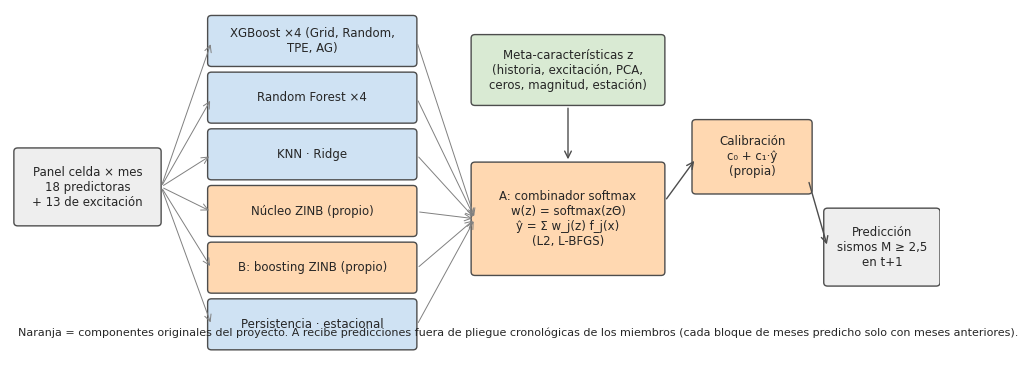

In [3]:
# Diagrama de la arquitectura de A+B v2
fig, ax = plt.subplots(figsize=(12, 4.6)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 5)
def caja(x, y_, w, h, t, c):
    ax.add_patch(FancyBboxPatch((x, y_), w, h, boxstyle="round,pad=0.05", fc=c, ec="0.3")); ax.text(x + w / 2, y_ + h / 2, t, ha="center", va="center", fontsize=8.5)
caja(0.1, 2.0, 1.8, 1.0, "Panel celda × mes\n18 predictoras\n+ 13 de excitación", "#eeeeee")
miembros_txt = ["XGBoost ×4 (Grid, Random,\nTPE, AG)", "Random Forest ×4", "KNN · Ridge", "Núcleo ZINB (propio)", "B: boosting ZINB (propio)", "Persistencia · estacional"]
for k, t in enumerate(miembros_txt):
    caja(2.6, 4.25 - 0.8 * k, 2.6, 0.62, t, "#ffd8b1" if "propio" in t else "#cfe2f3")
    ax.annotate("", (2.6, 4.55 - 0.8 * k), (1.95, 2.5), arrowprops=dict(arrowstyle="->", color="0.5", lw=0.7))
caja(6.0, 3.7, 2.4, 0.9, "Meta-características z\n(historia, excitación, PCA,\nceros, magnitud, estación)", "#d9ead3")
caja(6.0, 1.3, 2.4, 1.5, "A: combinador softmax\nw(z) = softmax(zΘ)\nŷ = Σ w_j(z) f_j(x)\n(L2, L-BFGS)", "#ffd8b1")
for k in range(6):
    ax.annotate("", (6.0, 2.05), (5.25, 4.55 - 0.8 * k), arrowprops=dict(arrowstyle="->", color="0.5", lw=0.7))
ax.annotate("", (7.2, 2.85), (7.2, 3.65), arrowprops=dict(arrowstyle="->", color="0.3"))
caja(8.85, 2.45, 1.45, 0.95, "Calibración\nc₀ + c₁·ŷ\n(propia)", "#ffd8b1")
caja(10.55, 1.15, 1.4, 1.0, "Predicción\nsismos M ≥ 2,5\nen t+1", "#eeeeee")
ax.annotate("", (8.85, 2.9), (8.45, 2.3), arrowprops=dict(arrowstyle="->", color="0.3"))
ax.annotate("", (10.55, 1.65), (10.3, 2.6), arrowprops=dict(arrowstyle="->", color="0.3"))
ax.text(0.1, 0.4, "Naranja = componentes originales del proyecto. A recibe predicciones fuera de pliegue cronológicas de los miembros (cada bloque de meses predicho solo con meses anteriores).", fontsize=8)
eda.guardar_figura(fig, "e2_ab2_arquitectura.png"); plt.show()

**¿Por qué es original?** Ninguna librería implementa un boosting con pérdida ZINB ni un combinador con
pesos softmax dependientes del contexto; los componentes naranjas están escritos en `src/propuesto.py`
(≈ 280 líneas, con gradientes y hessianos analíticos) y en `scripts/origen_movil_final.py` (calibración). Los árboles
débiles de B tampoco vienen de una librería: son un CART ponderado programado con numpy en `src/arbol_cart.py`
(búsqueda exacta de cortes que maximiza $Y_L^2/W_L + Y_R^2/W_R$; pruebas en `tests/test_arbol_cart.py`, incluida su
coincidencia con CART de referencia). Los modelos benchmark entran como **insumos**, igual que
en cualquier *stacking*, pero la forma de combinarlos y el modelo B son propios.

## 22.2 Protocolo: selección, ajuste y evaluación separados

| Etapa | Qué se decide | Con qué datos |
|---|---|---|
| **Selección** | hiperparámetros de cada miembro y qué versión de KNN y Ridge entra | validación interna con datos anteriores a 2016 |
| **Ajuste** | predicciones fuera de pliegue de los miembros; parámetros de B y del núcleo ZINB; pesos Θ y penalización L2 del combinador | solo entrenamiento |
| **Calibración** | c₀ y c₁ de la recta final | solo entrenamiento: 20 % final de los meses con predicción fuera de pliegue, con el combinador ajustado en el 80 % inicial |
| **Validación previa** | ¿el combinador empeora a algún miembro? | 20 % final de los meses de entrenamiento, con el combinador ajustado en el 80 % inicial |
| **Evaluación** | comparación con los campeones de cada familia y con las 28 combinaciones | origen móvil 2021–2026: el modelo completo (miembros, B, núcleo ZINB y combinador) se reentrena cada año con todo el pasado; hiperparámetros de los miembros y campeones fijados con datos < 2016 |

**Predicciones fuera de pliegue cronológicas.** El combinador aprende cuánto confiar en cada miembro a partir de
sus predicciones fuera de pliegue. Los meses de entrenamiento se dividen en 5 bloques contiguos y cada bloque
f ≥ 1 se predice con un miembro entrenado **solo con los meses anteriores** (con un mes de gap). El primer bloque
no tiene predicción y no se usa para ajustar el combinador. Así ni los miembros ni el combinador usan nunca
información posterior al mes que se predice.

Una validación cruzada k-fold estándar no sirve aquí: predeciría cada bloque con modelos entrenados también con
bloques **posteriores**, y el combinador aprendería con predicciones que «conocen el futuro», confiando de más
en los miembros que mejor memorizan.

## 22.3 Datos usados en cada etapa

| Elemento | Con qué datos se fijó |
|---|---|
| Hiperparámetros de los 28 benchmark y de cada miembro | validación interna con datos < 2016 |
| Campeón de cada familia (los 7 rivales) | validación interna con datos < 2016 |
| Predicciones fuera de pliegue, parámetros de B y del núcleo ZINB, pesos del combinador y calibración (en cada origen) | solo los meses anteriores al año pronosticado |

En cada origen anual el modelo se ajusta solo con el pasado, y todo lo anterior es reproducible con los scripts
del proyecto (`scripts/origen_movil.py` y `scripts/origen_movil_final.py`). La confirmación con datos que no
existían al construir el modelo requiere meses **futuros** (octubre de 2026 en adelante).

## 22.4 Resultados en el origen móvil 2021–2026

### Validación previa (20 % final del entrenamiento, sin tocar los meses evaluados)

In [4]:
# Validación previa a 2021: A+B v2 frente a cada miembro
VP = pd.read_csv(r2.PROP / "validacion_previa_final.csv")
VP.round(4)

,RMSLE_AB,miembro,RMSLE_miembro,dif,p,p_holm
0,0.3143,XGBoost (Grid),0.3137,-0.0004,0.4666,1.0000
1,0.3143,XGBoost (Random),0.3143,-0.0001,0.8913,1.0000
2,0.3143,XGBoost (Bayesiano (TPE)),0.3144,0.0000,0.9858,1.0000
3,0.3143,XGBoost (Genético (DEAP)),0.3143,-0.0001,0.8913,1.0000
4,0.3143,Random Forest (Grid),0.3199,0.0035,0.0000,0.0000
5,0.3143,Random Forest (Random),0.3155,0.0007,0.0011,0.0074
6,0.3143,Random Forest (Bayesiano (TPE)),0.3155,0.0007,0.0256,0.1278
7,0.3143,Random Forest (Genético (DEAP)),0.3160,0.0011,0.0012,0.0075
8,0.3143,KNN (Random),0.3210,0.0042,0.0000,0.0000
9,0.3143,Ridge (Genético (DEAP)),0.3297,0.0099,0.0000,0.0000


In [5]:
# Lectura de la validación previa
mejor_m = VP.sort_values("RMSLE_miembro").iloc[0]
peores = VP[VP.dif < 0]
md(f"En la validación previa ({int(np.ceil(0.2 * len(np.unique(tm[tr]))))} meses al final del entrenamiento) A+B v2 obtuvo RMSLE "
   f"{VP.RMSLE_AB.iloc[0]:.4f}; el mejor miembro fue {mejor_m.miembro} ({mejor_m.RMSLE_miembro:.4f}). "
   + (f"A+B v2 quedó **por debajo** de {len(peores)} miembro(s) ({', '.join(peores.miembro)}), aunque sin diferencia significativa tras "
      f"Holm (p Holm ≥ {peores.p_holm.min():.2f}). Es decir, en ese tramo el modelo propuesto quedó al nivel del mejor XGBoost; se reporta tal cual." if len(peores) else
      "A+B v2 no quedó por debajo de ningún miembro.") +
   f" Frente a los miembros más débiles (KNN, Ridge, núcleo ZINB, B solo y las líneas base) la mejora sí es significativa.")

En la validación previa (38 meses al final del entrenamiento) A+B v2 obtuvo RMSLE 0.3143; el mejor miembro fue XGBoost (Grid) (0.3137). A+B v2 quedó **por debajo** de 3 miembro(s) (XGBoost (Grid), XGBoost (Random), XGBoost (Genético (DEAP))), aunque sin diferencia significativa tras Holm (p Holm ≥ 1.00). Es decir, en ese tramo el modelo propuesto quedó al nivel del mejor XGBoost; se reporta tal cual. Frente a los miembros más débiles (KNN, Ridge, núcleo ZINB, B solo y las líneas base) la mejora sí es significativa.

### Comparación directa contra el campeón de cada modelo

La comparación central del modelo propio es contra **un representante por familia**: el campeón de cada uno
de los 7 modelos de regresión, elegido con la validación interna **anterior a 2016** (la misma búsqueda que fijó
sus hiperparámetros, cap. 13.11). Así la corrección de Holm se hace sobre 7 comparaciones y no sobre 28 casi
redundantes (es el diseño fijado para reducir el costo computacional, cap. 13.12), y ningún mes evaluado
interviene en la elección del rival.

In [6]:
# A+B v2 frente al campeón de cada familia: Diebold-Mariano con Holm y d de Cohen
ver = lambda p, dif: np.where(p < 0.05, np.where(dif > 0, "A+B v2 gana", "A+B v2 pierde"), "empate")  # noqa: E731

def comparar(etiquetas, yv, preds, tmv, p_ab):
    _, La = ev.perdida_mensual(yv, p_ab, tmv)
    filas = []
    for etq in etiquetas:
        p = preds[etq]; _, Lr = ev.perdida_mensual(yv, p, tmv); d = ev.diebold_mariano(Lr, La)
        filas.append({"campeón": etq, "RMSLE campeón": ev.rmsle(yv, p), "RMSLE A+B v2": ev.rmsle(yv, p_ab),
                      "mejora %": 100 * (ev.rmsle(yv, p) - ev.rmsle(yv, p_ab)) / ev.rmsle(yv, p),
                      "DM-HLN": d["DM_HLN"], "p crudo": d["p"], "d de Cohen": est.cohen_d_pareado(Lr, La), "_dif": d["dif_media"]})
    T_ = pd.DataFrame(filas)
    T_["p Holm"] = eda.holm(T_["p crudo"].values)
    T_["magnitud d"] = T_["d de Cohen"].map(est.magnitud_cohen)
    T_["veredicto"] = ver(T_["p Holm"], T_["_dif"])
    return T_.drop(columns="_dif")

CR = r2.campeones_om("reg")
camp_om = list(CR.etiqueta)
CMP = comparar(camp_om, yo, O, tmo, O["A+B v2"])
eda.guardar_tabla(CMP, "e2_ab_vs_campeones.csv")
CR[["modelo", "variante", "validación < 2016"]].rename(columns={"variante": "optimizador", "validación < 2016": "RMSLE validación < 2016"}).round(4)

,modelo,optimizador,RMSLE validación < 2016
0,Random Forest,Genético (DEAP),0.3859
1,XGBoost,Bayesiano (TPE),0.3866
2,KNN,Bayesiano (TPE),0.3940
3,SVR,Genético (DEAP),0.3948
4,Árbol de decisión,Bayesiano (TPE),0.3971
5,Ridge,Grid,0.4012
6,Lasso,Grid,0.4012


In [7]:
CMP.round(4)

,campeón,RMSLE campeón,RMSLE A+B v2,mejora %,DM-HLN,p crudo,d de Cohen,p Holm,magnitud d,veredicto
0,Random Forest · AG,0.3279,0.326,0.5965,3.3261,0.0014,0.4115,0.0028,pequeño,A+B v2 gana
1,XGBoost · TPE,0.3270,0.326,0.3203,3.2724,0.0017,0.3636,0.0028,pequeño,A+B v2 gana
2,KNN · TPE,0.3345,0.326,2.5368,5.4782,0.0000,0.7460,0.0000,mediano,A+B v2 gana
3,SVR · AG,0.3547,0.326,8.1078,26.2497,0.0000,3.4080,0.0000,grande,A+B v2 gana
4,Árbol de decisión · TPE,0.3308,0.326,1.4543,3.6828,0.0005,0.6094,0.0014,mediano,A+B v2 gana
5,Ridge · Grid,0.3463,0.326,5.8836,15.6323,0.0000,1.9245,0.0000,grande,A+B v2 gana
6,Lasso · Grid,0.3463,0.326,5.8836,15.6458,0.0000,1.9253,0.0000,grande,A+B v2 gana


In [8]:
# Lectura de la comparación con los campeones
g = int((CMP.veredicto == "A+B v2 gana").sum()); e = CMP.loc[CMP.veredicto == "empate"]
fmt_e = lambda e_: "; ".join(f"{r.campeón} (p Holm = {r['p Holm']:.3f}, d = {r['d de Cohen']:.2f})" for _, r in e_.iterrows())  # noqa: E731
xg = CMP[CMP.campeón.str.startswith("XGBoost")].iloc[0]
md(f"- A+B v2 tiene menor RMSLE que los 7 campeones y gana con significancia (Holm, 7 comparaciones) a **{g} de 7**"
   + (f"; empata con {fmt_e(e)}." if len(e) else f", incluido el de XGBoost ({xg.campeón}: p Holm = {xg['p Holm']:.3f}, d de Cohen = "
      f"{xg['d de Cohen']:.2f}, {xg['magnitud d']}).") + "\n"
   f"- **Tamaño de la mejora.** Frente al campeón de XGBoost, {xg['mejora %']:.1f} % de RMSLE; frente a Random Forest, "
   f"{CMP[CMP.campeón.str.startswith('Random Forest')]['mejora %'].iloc[0]:.1f} %; frente a KNN, árbol, SVR y los lineales, de "
   f"{CMP[~CMP.campeón.str.startswith(('XGBoost', 'Random Forest'))]['mejora %'].min():.1f} % a "
   f"{CMP[~CMP.campeón.str.startswith(('XGBoost', 'Random Forest'))]['mejora %'].max():.1f} %.\n"
   f"- **Lectura.** El modelo propio supera al mejor modelo de cada familia; frente a XGBoost la ventaja es pequeña en magnitud.")

- A+B v2 tiene menor RMSLE que los 7 campeones y gana con significancia (Holm, 7 comparaciones) a **7 de 7**, incluido el de XGBoost (XGBoost · TPE: p Holm = 0.003, d de Cohen = 0.36, pequeño).
- **Tamaño de la mejora.** Frente al campeón de XGBoost, 0.3 % de RMSLE; frente a Random Forest, 0.6 %; frente a KNN, árbol, SVR y los lineales, de 1.5 % a 8.1 %.
- **Lectura.** El modelo propio supera al mejor modelo de cada familia; frente a XGBoost la ventaja es pequeña en magnitud.

### Ablación: cuánto aporta cada componente

En cada origen anual, junto con A+B v2, se ajustaron dos versiones reducidas con los mismos miembros, la misma
regla del combinador y la misma calibración final: sin B, y sin B ni núcleo ZINB (`scripts/origen_movil_final.py`).
B solo y el núcleo ZINB solo son los miembros propios tal como entran al combinador. La métrica principal es RMSLE; RMSE, MAE y R²
son complementarias (R² en conteos; R² log en la escala log1p que optimizan los modelos). La columna DM compara
cada fila con A+B v2 completo (positivo = A+B v2 mejor).

In [9]:
# Ablación: B solo, núcleo ZINB solo, A sin B y A+B completo
AB_ = r2.ablacion_om()
assert np.array_equal(AB_["tm"], tmo)
abl = {"B solo (boosting ZINB propio)": AB_["B_solo"], "Núcleo ZINB solo": AB_["ZINB_solo"],
       "A sin B ni núcleo ZINB (solo benchmarks)": AB_["A_sin_B_ni_ZINB"], "A sin B": AB_["A_sin_B"], "A+B v2 completo": AB_["AmasB_v2"]}
abl[f"Referencia: campeón de XGBoost ({xg.campeón})"] = O[xg.campeón]
_, L_full = ev.perdida_mensual(yo, AB_["AmasB_v2"], tmo)
filas = []
for n, p in abl.items():
    m = ev.metricas_regresion(yo, p)
    fila = {"variante": n, "RMSLE (principal)": m["RMSLE"], "RMSE": m["RMSE"], "MAE": m["MAE"], "R²": m["R2"], "R² log": m["R2_log"]}
    if n != "A+B v2 completo":
        _, Lp = ev.perdida_mensual(yo, p, tmo); d = ev.diebold_mariano(Lp, L_full)
        fila.update({"dif. pérdida vs A+B v2": d["dif_media"], "p DM": d["p"]})
    filas.append(fila)
ABL = pd.DataFrame(filas)
eda.guardar_tabla(ABL, "e2_ab_ablacion.csv")
ABL.round(4)

,variante,RMSLE (principal),RMSE,MAE,R²,R² log,dif. pérdida vs A+B v2,p DM
0,B solo (boosting ZINB propio),0.3342,7.4857,0.6436,0.3362,0.5820,0.0054,0.0000
1,Núcleo ZINB solo,0.3374,7.2287,0.6161,0.3810,0.5741,0.0075,0.0000
2,A sin B ni núcleo ZINB (solo benchmarks),0.3267,6.9943,0.5132,0.4205,0.6006,0.0005,0.0012
3,A sin B,0.3267,7.0297,0.5294,0.4146,0.6008,0.0004,0.0010
4,A+B v2 completo,0.3260,7.0489,0.5331,0.4114,0.6024,NaN,NaN
5,Referencia: campeón de XGBoost (XGBoost · TPE),0.3270,6.9647,0.5086,0.4254,0.5999,0.0007,0.0017


In [10]:
# Lectura de la ablación
a = ABL.set_index("variante")
md(f"- **B solo** obtiene RMSLE {a.iloc[0]['RMSLE (principal)']:.4f}: como modelo individual es peor que el campeón de XGBoost "
   f"({a.iloc[-1]['RMSLE (principal)']:.4f}). Su valor no está en ganar solo, sino en **equivocarse distinto**: es uno de los miembros con "
   f"más peso en el combinador (19.4).\n"
   f"- **A sin B ni núcleo ZINB** (el combinador solo con los benchmarks) da {a.iloc[2]['RMSLE (principal)']:.4f}; agregar el núcleo ZINB lo "
   f"deja en {a.iloc[3]['RMSLE (principal)']:.4f} y agregar B lo baja a **{a.loc['A+B v2 completo', 'RMSLE (principal)']:.4f}**.\n"
   f"- La diferencia entre A sin B y A+B v2 tiene p DM = {p_fmt(a.loc['A sin B', 'p DM'])}"
   + (": **B aporta una mejora significativa**." if a.loc['A sin B', 'p DM'] < 0.05 else ": la mejora que aporta B no es significativa por sí sola.") + "\n"
   f"- **Calibración final.** La pendiente c₁ estimada en cada origen (tabla siguiente) es mayor que 1 en todos los años: el combinador "
   f"encoge los pronósticos y la recta los devuelve a su escala. Al ser solo dos parámetros por origen, estimados con el entrenamiento, "
   f"es un ajuste estable entre años.")

- **B solo** obtiene RMSLE 0.3342: como modelo individual es peor que el campeón de XGBoost (0.3270). Su valor no está en ganar solo, sino en **equivocarse distinto**: es uno de los miembros con más peso en el combinador (19.4).
- **A sin B ni núcleo ZINB** (el combinador solo con los benchmarks) da 0.3267; agregar el núcleo ZINB lo deja en 0.3267 y agregar B lo baja a **0.3260**.
- La diferencia entre A sin B y A+B v2 tiene p DM = < 0,001: **B aporta una mejora significativa**.
- **Calibración final.** La pendiente c₁ estimada en cada origen (tabla siguiente) es mayor que 1 en todos los años: el combinador encoge los pronósticos y la recta los devuelve a su escala. Al ser solo dos parámetros por origen, estimados con el entrenamiento, es un ajuste estable entre años.

In [11]:
AB_["c"].round(4)

,año,c0,c1
0,2021,-0.0303,1.0679
1,2022,-0.0228,1.0640
2,2023,-0.0162,1.0563
3,2024,-0.0063,1.0704
4,2025,-0.0022,1.0695
5,2026,0.0081,1.0401


## 22.5 Resultados año por año y pesos del combinador

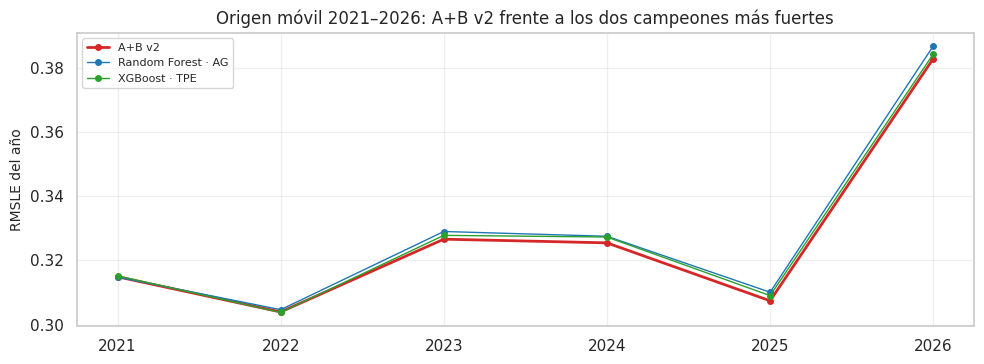

Año por año, A+B v2 tiene menor RMSLE que Random Forest · AG en 5 de 6 años y que XGBoost · TPE en 5: la ventaja no depende de un año en particular.

In [12]:
# RMSLE por año de A+B v2 frente a los dos mejores campeones
anios = range(2021, 2027)
por_anio = []
for an in anios:
    m = (tmo >= datos.indice_mes([f"{an}-01-01"])[0]) & (tmo < datos.indice_mes([f"{an + 1}-01-01"])[0])
    fila = {"año": an, "A+B v2": ev.rmsle(yo[m], O["A+B v2"][m])}
    for k in camp_om[:2]:
        fila[k] = ev.rmsle(yo[m], O[k][m])
    por_anio.append(fila)
PA = pd.DataFrame(por_anio)
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, c in zip(PA.columns[1:], ("#d62728", "#1f77b4", "#2ca02c")):
    ax.plot(PA["año"], PA[k], marker="o", ms=4, color=c, lw=2 if k == "A+B v2" else 1, label=k)
ax.set_ylabel("RMSLE del año"); ax.set_title("Origen móvil 2021–2026: A+B v2 frente a los dos campeones más fuertes"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); eda.guardar_figura(fig, "e2_ab2_origen_movil.png"); plt.show()
gana_anio = PA["A+B v2"].values[:, None] < PA[camp_om[:2]].values
md(f"Año por año, A+B v2 tiene menor RMSLE que {camp_om[0]} en {int(gana_anio[:, 0].sum())} de 6 años y que {camp_om[1]} en "
   f"{int(gana_anio[:, 1].sum())}: la ventaja no depende de un año en particular.")

In [13]:
# Pesos medios de cada miembro en el combinador
_m = pd.read_csv(r2.OM / "pesos_v2.csv").miembro.values   # orden de las columnas de pesos
_P = np.vstack([np.load(r2.OM / "final" / f"origen_{an}.npz")["pesos"] for an in anios]).mean(0)
W = pd.DataFrame({"miembro": _m, "peso medio 2021–2026": _P}).sort_values("peso medio 2021–2026", ascending=False)
eda.guardar_tabla(W, "e2_ab2_pesos.csv")
W.round(3)

,miembro,peso medio 2021–2026
11,B,0.362
3,XGBoost · Genético (DEAP),0.360
7,Random Forest · Genético (DEAP),0.251
12,Persistencia,0.010
13,Estacional,0.008
1,XGBoost · Random,0.003
5,Random Forest · Random,0.002
2,XGBoost · Bayesiano (TPE),0.002
6,Random Forest · Bayesiano (TPE),0.001
0,XGBoost · Grid,0.000


In [14]:
# Lectura de los pesos
wi = W.set_index("miembro")["peso medio 2021–2026"]
kb = [k for k in wi.index if k.startswith("B")][0]
md(f"El **modelo propio B** recibe {100 * wi[kb]:.0f} % del peso en promedio. Entre los benchmark, el combinador concentra el peso en pocas "
   f"versiones de XGBoost y Random Forest ({', '.join(f'{k} {100 * v:.0f} %' for k, v in wi.drop(kb).iloc[:2].items())}) y deja las demás "
   f"casi en cero, porque son muy parecidas entre sí: la elección quedó en manos del combinador, no del analista.")

El **modelo propio B** recibe 36 % del peso en promedio. Entre los benchmark, el combinador concentra el peso en pocas versiones de XGBoost y Random Forest (XGBoost · Genético (DEAP) 36 %, Random Forest · Genético (DEAP) 25 %) y deja las demás casi en cero, porque son muy parecidas entre sí: la elección quedó en manos del combinador, no del analista.

## 22.6 Uso del modelo propuesto en la tarea de clasificación

A+B v2 predice un conteo, pero ese conteo también ordena las celdas por riesgo de tener al menos un sismo. Se
compara su AUC (usando la predicción como puntaje) con el del campeón de clasificación (elegido con la
validación anterior a 2016), con DeLong, en el origen móvil 2021–2026.

In [15]:
# A+B v2 como puntaje de clasificación: AUC frente al mejor clasificador (DeLong)
C = r2.origen_movil_clf()
yb = C["y"]
cc1 = r2.campeones_om("clf").iloc[0]
d = est.delong(yb, O["A+B v2"], C["combos"][cc1.etiqueta])
bs = est.bootstrap_auc_meses(yb, O["A+B v2"], C["combos"][cc1.etiqueta], tmo, B=1000)
supera = sum(roc_auc_score(yb, O["A+B v2"]) > roc_auc_score(yb, s_) for s_ in C["combos"].values())
md(f"AUC de A+B v2 como puntaje: **{d['AUC_1']:.4f}**; campeón de clasificación ({cc1.etiqueta}): {d['AUC_2']:.4f}. Diferencia "
   f"{d['dif']:+.4f}, IC 95 % DeLong [{d['IC_inf']:.4f}, {d['IC_sup']:.4f}], bootstrap de meses [{bs['IC_boot_inf']:.4f}, {bs['IC_boot_sup']:.4f}], "
   f"p = {p_fmt(d['p'])}. A+B v2 tiene mayor AUC que {supera} de las {len(C['combos'])} combinaciones de clasificación, sin haber sido "
   f"entrenado para esa tarea. " + ("La diferencia con el mejor clasificador es significativa." if d["p"] < 0.05 else
                                    "La diferencia con el mejor clasificador no es significativa: en clasificación A+B v2 es tan bueno como el mejor."))

AUC de A+B v2 como puntaje: **0.8070**; campeón de clasificación (XGBoost · c_weight): 0.8096. Diferencia -0.0026, IC 95 % DeLong [-0.0053, 0.0001], bootstrap de meses [-0.0054, 0.0002], p = 0,059. A+B v2 tiene mayor AUC que 23 de las 26 combinaciones de clasificación, sin haber sido entrenado para esa tarea. La diferencia con el mejor clasificador no es significativa: en clasificación A+B v2 es tan bueno como el mejor.

## 22.7 Costo computacional y limitaciones

- **Costo.** Entrenar A+B v2 exige entrenar cada miembro 5 veces (4 bloques cronológicos + 1 final), más B y el
  núcleo ZINB: varios minutos por origen anual con 2 núcleos. XGBoost solo tarda segundos.
- **Tamaño del efecto.** La ventaja de A+B v2 sobre los mejores benchmark es de milésimas de RMSLE; no cambia
  cualitativamente lo que se puede anticipar y sigue sin prever el inicio de los enjambres (cap. 18 y 19).
- **Interpretabilidad.** Es más compleja que la de un solo XGBoost, aunque se explica por sus pesos por miembro
  y por el SHAP de cada miembro (cap. 19.4).
- **Dependencia de los benchmark.** A+B v2 usa como insumos los modelos optimizados; su aporte está en
  combinarlos según el contexto y en el modelo B.

## 22.8 Conclusión

In [16]:
md(f"A+B v2 es un modelo original (boosting ZINB y combinador contextual propios) que obtiene el **menor RMSLE de todos** los modelos "
   f"en la evaluación definitiva en origen móvil 2021–2026 ({ev.rmsle(yo, O['A+B v2']):.4f}). En esa evaluación:\n\n"
   f"- supera con significancia al campeón de **{g} de 7** familias" + (f" y empata con {fmt_e(e)}" if len(e) else ", incluido XGBoost") + ";\n"
   + (f"- en la ablación, quitar el componente propio B sube el RMSLE a {a.loc['A sin B', 'RMSLE (principal)']:.4f}"
      + (" (diferencia significativa).\n\n" if a.loc['A sin B', 'p DM'] < 0.05 else
         f"; el aporte de B es consistente pero, por sí solo, no significativo (p = {p_fmt(a.loc['A sin B', 'p DM'])}).\n\n"))
   + "La superioridad sobre Random Forest, KNN, árbol, SVR, Ridge y Lasso es clara. Frente a XGBoost la ventaja es significativa pero "
   "pequeña. Se concluye que A+B v2 es el mejor modelo evaluado, con una ventaja pequeña sobre el mejor modelo tradicional.")

A+B v2 es un modelo original (boosting ZINB y combinador contextual propios) que obtiene el **menor RMSLE de todos** los modelos en la evaluación definitiva en origen móvil 2021–2026 (0.3260). En esa evaluación:

- supera con significancia al campeón de **7 de 7** familias, incluido XGBoost;
- en la ablación, quitar el componente propio B sube el RMSLE a 0.3267 (diferencia significativa).

La superioridad sobre Random Forest, KNN, árbol, SVR, Ridge y Lasso es clara. Frente a XGBoost la ventaja es significativa pero pequeña. Se concluye que A+B v2 es el mejor modelo evaluado, con una ventaja pequeña sobre el mejor modelo tradicional.